# Store Sales – Time Series Forecasting (Corporación Favorita)

Goal: forecast `sales` for 1,782 store × product-family series (54 stores × 33 families) for the
**16 days 2017-08-16 → 2017-08-31**. Metric: **RMSLE**.

**Plan**

1. **EDA** – trend, seasonality, zero-sales series, promotions, holidays, oil, the 2016 earthquake.
2. **Feature engineering** – a *multi-origin, direct multi-horizon* design: for a forecast origin `T`
   (last day with known sales) we build features from history ≤ `T` and one row per horizon `h = 1..16`.
   This mirrors exactly what we face at test time (origin = 2017-08-15), so there is no leakage and no
   recursive error accumulation.
3. **Models** – naive baselines → Ridge → LightGBM → XGBoost → blend, all scored on a hold-out
   window that mimics the test window.
4. **Submission** – refit on all data and write `submission.csv`.

Because every model predicts `log1p(sales)`, RMSE in log space **is** the RMSLE.

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

# plotting style: thin marks, recessive grid, fixed categorical order
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({
    'figure.figsize': (12, 4), 'figure.dpi': 90, 'axes.prop_cycle': plt.cycler(color=PALETTE),
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 1.6, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'legend.frameon': False,
})
BLUE, ORANGE, GREY = PALETTE[0], PALETTE[1], '#9a9890'
print('pandas', pd.__version__, '| lightgbm', lgb.__version__, '| xgboost', xgb.__version__)

pandas 3.1.0 | lightgbm 4.7.0 | xgboost 3.2.0


In [2]:
DATA = Path('.')
train = pd.read_csv(DATA / 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA / 'test.csv', parse_dates=['date'])
stores = pd.read_csv(DATA / 'stores.csv')
oil = pd.read_csv(DATA / 'oil.csv', parse_dates=['date'])
hol = pd.read_csv(DATA / 'holidays_events.csv', parse_dates=['date'])
trans = pd.read_csv(DATA / 'transactions.csv', parse_dates=['date'])

for name, df in [('train', train), ('test', test), ('stores', stores), ('oil', oil),
                 ('holidays', hol), ('transactions', trans)]:
    rng = f"{df.date.min().date()} → {df.date.max().date()}" if 'date' in df else ''
    print(f"{name:13s} {str(df.shape):16s} {rng}")
train.head()

train         (3000888, 6)     2013-01-01 → 2017-08-15
test          (28512, 5)       2017-08-16 → 2017-08-31
stores        (54, 5)          
oil           (1218, 2)        2013-01-01 → 2017-08-31
holidays      (350, 6)         2012-03-02 → 2017-12-26
transactions  (83488, 3)       2013-01-01 → 2017-08-15


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 1. Exploratory data analysis
### 1.1 Data integrity

In [3]:
all_days = pd.date_range(train.date.min(), train.date.max())
missing = all_days.difference(train.date.unique())
print('Missing dates in train:', [d.date() for d in missing])
print('Rows per date (should be 1782):', train.groupby('date').size().unique())
print('Series:', train.groupby(['store_nbr', 'family']).ngroups,
      '| stores:', train.store_nbr.nunique(), '| families:', train.family.nunique())
print('Negative sales:', (train.sales < 0).sum(), '| NaN sales:', train.sales.isna().sum())
print('Share of rows with zero sales: {:.1%}'.format((train.sales == 0).mean()))
print('Oil NaNs:', oil.dcoilwtico.isna().sum(), 'of', len(oil), '(oil only has weekdays)')

Missing dates in train: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
Rows per date (should be 1782): [1782]
Series: 1782 | stores: 54 | families: 33
Negative sales: 0 | NaN sales: 0
Share of rows with zero sales: 31.3%
Oil NaNs: 43 of 1218 (oil only has weekdays)


### 1.2 Overall trend and the earthquake

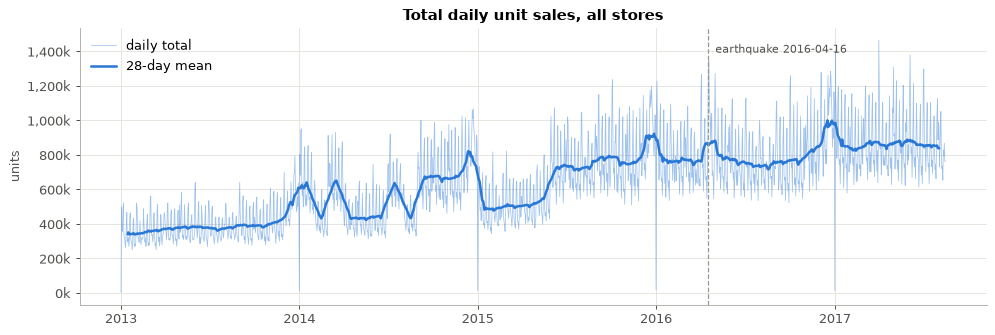

Days with near-zero total sales (store closures): [datetime.date(2013, 1, 1), datetime.date(2014, 1, 1)]


In [4]:
daily = train.groupby('date').sales.sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, color=BLUE, lw=0.6, alpha=0.45, label='daily total')
ax.plot(daily.index, daily.rolling(28, center=True).mean(), color=BLUE, lw=2, label='28-day mean')
ax.axvline(pd.Timestamp('2016-04-16'), color=GREY, ls='--', lw=1)
ax.annotate('earthquake 2016-04-16', (pd.Timestamp('2016-04-16'), daily.max() * 0.95),
            xytext=(6, 0), textcoords='offset points', color='#52514e', fontsize=9)
ax.set_title('Total daily unit sales, all stores')
ax.set_ylabel('units'); ax.legend(loc='upper left')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}k'))
plt.show()
print('Days with near-zero total sales (store closures):', [d.date() for d in daily[daily < 1e4].index])

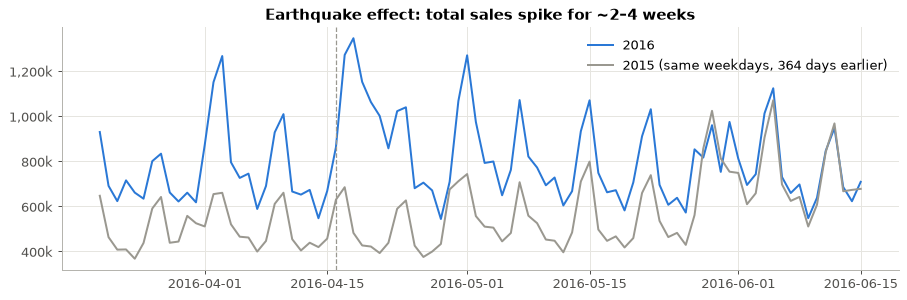

Sales 2016-04-17..05-15 vs same weeks 2015: +67.2%


In [5]:
# Earthquake: compare Apr–May 2016 to the same weekday-aligned window in 2015 (364 days earlier)
w16 = daily['2016-03-20':'2016-06-15']
w15 = daily.reindex(w16.index - pd.Timedelta(days=364))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(w16.index, w16.values, color=BLUE, label='2016')
ax.plot(w16.index, w15.values, color=GREY, label='2015 (same weekdays, 364 days earlier)')
ax.axvline(pd.Timestamp('2016-04-16'), color=GREY, ls='--', lw=1)
ax.set_title('Earthquake effect: total sales spike for ~2–4 weeks')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}k')); ax.legend()
plt.show()
uplift = w16['2016-04-17':'2016-05-15'].sum() / w15.loc[w16['2016-04-17':'2016-05-15'].index - pd.Timedelta(days=364)].sum()
print(f'Sales 2016-04-17..05-15 vs same weeks 2015: {uplift - 1:+.1%}')

### 1.3 Product families and stores

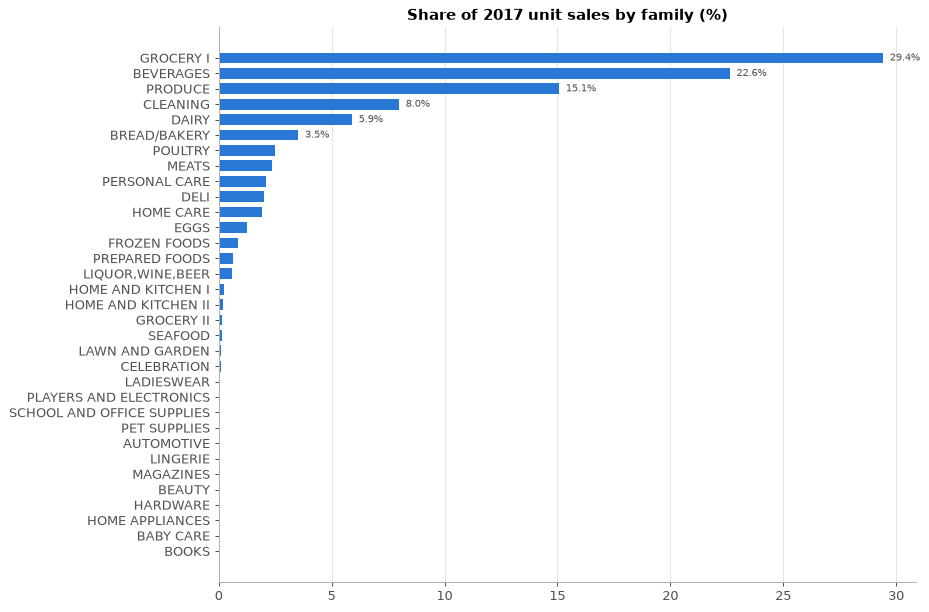

Top 5 families = 81% of units


In [6]:
recent = train[train.date >= '2017-01-01']
fam = recent.groupby('family').sales.sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(fam.index, fam.values / fam.sum() * 100, color=BLUE, height=0.7)
ax.set_title('Share of 2017 unit sales by family (%)'); ax.grid(axis='y', visible=False)
for y, v in enumerate(fam.values / fam.sum() * 100):
    if v > 3: ax.text(v + 0.3, y, f'{v:.1f}%', va='center', fontsize=8, color='#52514e')
plt.show()
print('Top 5 families =', f'{fam.tail(5).sum() / fam.sum():.0%}', 'of units')

Average daily units per store, by store type (2017):


,count,mean,min,max
type,,,,
A,9,31243.0,11877.0,46212.0
B,8,15142.0,11322.0,20373.0
C,15,8382.0,4981.0,15440.0
D,18,15195.0,5124.0,38380.0
E,4,13509.0,12112.0,15067.0


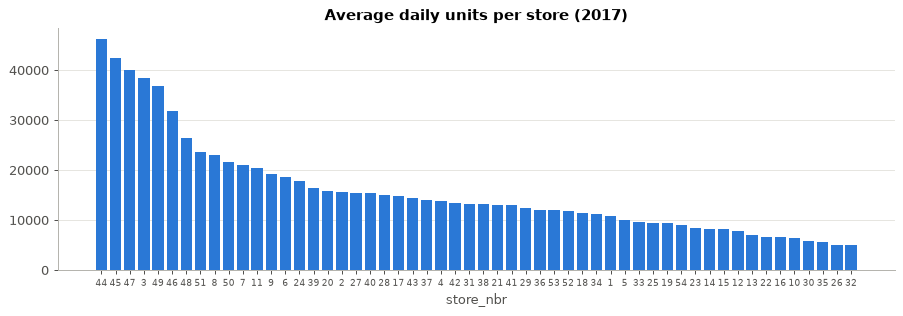

In [7]:
st = recent.groupby('store_nbr').sales.sum().div(recent.date.nunique()).rename('daily_units').reset_index()
st = st.merge(stores, on='store_nbr')
by_type = st.groupby('type').daily_units.agg(['count', 'mean', 'min', 'max']).round(0)
print('Average daily units per store, by store type (2017):'); display(by_type)
fig, ax = plt.subplots(figsize=(12, 3.5))
order = st.sort_values('daily_units', ascending=False)
ax.bar(order.store_nbr.astype(str), order.daily_units, color=BLUE, width=0.8)
ax.set_title('Average daily units per store (2017)'); ax.set_xlabel('store_nbr'); ax.tick_params(axis='x', labelsize=7)
ax.grid(axis='x', visible=False); plt.show()

### 1.4 Zero-sales series
Many store × family combinations never sell anything (e.g. a store that does not stock BOOKS).
These are easy wins: predicting exactly 0 gives zero error.

In [8]:
last = train[train.date > train.date.max() - pd.Timedelta(days=56)]
s56 = last.groupby(['store_nbr', 'family']).sales.sum()
dead = s56[s56 == 0]
print(f'Series with zero sales in the last 56 days: {len(dead)} of {len(s56)}')
print('By family:'); print(dead.reset_index().family.value_counts().head(10).to_string())

ever = train.groupby(['store_nbr', 'family']).sales.sum()
print(f'\nSeries that NEVER sold anything: {(ever == 0).sum()}')

Series with zero sales in the last 56 days: 96 of 1782
By family:
family
BOOKS                         38
BABY CARE                     23
LAWN AND GARDEN               14
LADIESWEAR                    11
SCHOOL AND OFFICE SUPPLIES    10

Series that NEVER sold anything: 53


### 1.5 Seasonality: day of week and payday

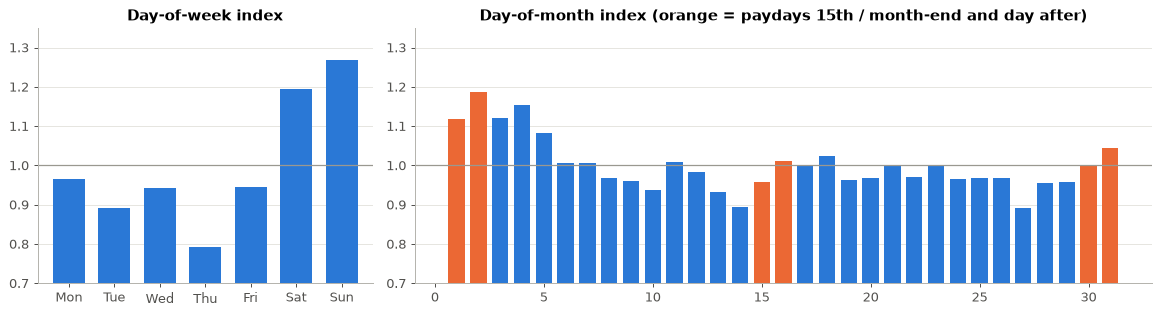

dow
Mon    0.965
Tue    0.893
Wed    0.943
Thu    0.791
Fri    0.945
Sat    1.195
Sun    1.267


In [9]:
r = train[train.date >= '2016-06-01'].groupby('date').sales.sum().to_frame('sales')
r['dow'] = r.index.dayofweek; r['dom'] = r.index.day
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1, 2.2]})
dow = r.groupby('dow').sales.mean()
axes[0].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], dow / dow.mean(), color=BLUE, width=0.7)
axes[0].axhline(1, color=GREY, lw=1); axes[0].set_title('Day-of-week index'); axes[0].set_ylim(0.7, 1.35)
axes[0].grid(axis='x', visible=False)
dom = r.groupby('dom').sales.mean()
cols = [ORANGE if d in (1, 2, 15, 16, 30, 31) else BLUE for d in dom.index]
axes[1].bar(dom.index, dom / dom.mean(), color=cols, width=0.75)
axes[1].axhline(1, color=GREY, lw=1); axes[1].set_title('Day-of-month index (orange = paydays 15th / month-end and day after)')
axes[1].set_ylim(0.7, 1.35); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(dow.div(dow.mean()).round(3).rename(index=dict(enumerate(['Mon','Tue','Wed','Thu','Fri','Sat','Sun']))).to_string())

### 1.6 Promotions

In [10]:
p = train[train.date >= '2016-01-01'][['family', 'sales', 'onpromotion']].copy()
p['promo_bin'] = pd.cut(p.onpromotion, [-1, 0, 5, 20, 50, 1000], labels=['0', '1–5', '6–20', '21–50', '>50'])
tab = p.groupby('promo_bin', observed=True).agg(rows=('sales', 'size'), mean_sales=('sales', 'mean'),
                                                 mean_log1p=('sales', lambda s: np.log1p(s).mean()))
display(tab.round(2))
# within-family comparison removes the "big families have more promos" confound
fam_lift = (p.assign(promo=p.onpromotion > 0).groupby(['family', 'promo']).sales.mean().unstack())
fam_lift['lift'] = fam_lift[True] / fam_lift[False]
print('Median within-family lift (mean sales with promo / without):', round(fam_lift.lift.median(), 2))
print('Spearman corr(onpromotion, sales):', round(p[['onpromotion', 'sales']].corr('spearman').iloc[0, 1], 3))

,rows,mean_sales,mean_log1p
promo_bin,,,
0,643896,83.40,2.09
1–5,203669,370.35,4.62
6–20,119522,884.00,6.09
21–50,57124,2281.97,7.25
>50,30733,3830.71,7.80


Median within-family lift (mean sales with promo / without): 1.74
Spearman corr(onpromotion, sales): 0.714


### 1.7 Oil price
Ecuador is oil-dependent. Two separate panels (rather than a dual-axis chart) to compare shape:

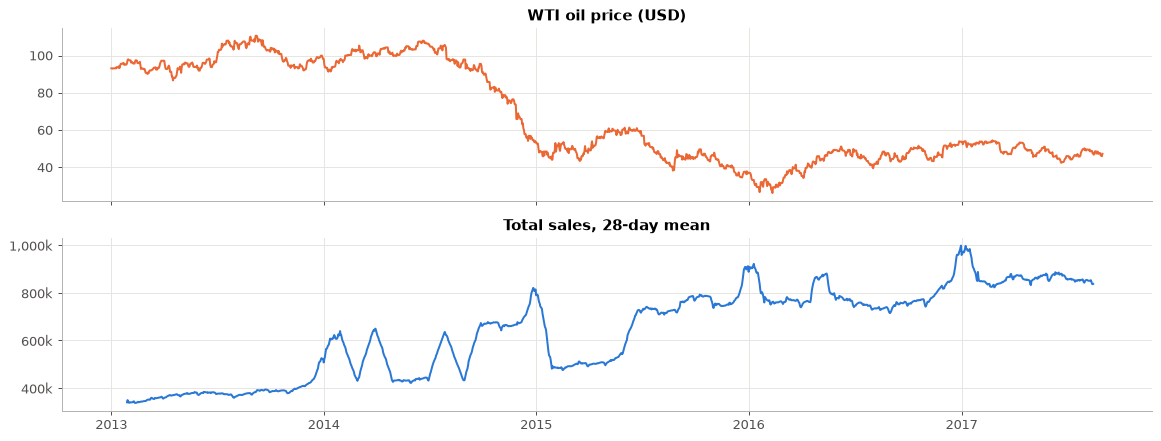

Monthly corr(oil, sales): -0.788 → mostly the shared trend (oil fell while sales grew); weak signal for a 16-day horizon.


In [11]:
o = oil.set_index('date').dcoilwtico.reindex(pd.date_range(oil.date.min(), oil.date.max())).ffill().bfill()
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(o.index, o.values, color=ORANGE); axes[0].set_title('WTI oil price (USD)')
axes[1].plot(daily.index, daily.rolling(28).mean(), color=BLUE); axes[1].set_title('Total sales, 28-day mean')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}k'))
plt.tight_layout(); plt.show()
m = pd.concat([o.rename('oil'), daily.rename('sales')], axis=1, join='inner').resample('MS').mean()
print('Monthly corr(oil, sales):', round(m.corr().iloc[0, 1], 3),
      '→ mostly the shared trend (oil fell while sales grew); weak signal for a 16-day horizon.')

### 1.8 Holidays & events
Handling rules (from the data description):
* `transferred == True` rows are **ordinary days** → dropped.
* `Transfer`, `Additional`, `Bridge` rows are **days off** → treated as holidays.
* `Work Day` → a normally-off day that is worked (flag separately).
* `Event` → national events (Mother's Day, World Cup, earthquake aftermath, Black Friday…).
* National → all stores; Regional → stores in that `state`; Local → stores in that `city`.

In [12]:
print(hol.groupby(['type', 'locale']).size().unstack(fill_value=0))
print('\nTransferred rows:', hol.transferred.sum())
print(hol[hol.date.between('2017-08-01', '2017-08-31')].to_string())

locale      Local  National  Regional
type                                 
Additional     11        40         0
Bridge          0         5         0
Event           0        56         0
Holiday       137        60        24
Transfer        4         8         0
Work Day        0         5         0

Transferred rows: 12
          date      type    locale locale_name                             description  transferred
323 2017-08-05   Holiday     Local  Esmeraldas                 Fundacion de Esmeraldas        False
324 2017-08-10   Holiday  National     Ecuador           Primer Grito de Independencia         True
325 2017-08-11  Transfer  National     Ecuador  Traslado Primer Grito de Independencia        False
326 2017-08-15   Holiday     Local    Riobamba                   Fundacion de Riobamba        False
327 2017-08-24   Holiday     Local      Ambato                     Fundacion de Ambato        False


In [13]:
h = hol[~hol.transferred.astype(bool)].copy()
DAYOFF = ['Holiday', 'Transfer', 'Additional', 'Bridge']
nat = h[h.locale == 'National']
nat_off = set(nat[nat.type.isin(DAYOFF)].date)
nat_event = set(nat[nat.type == 'Event'].date)
nat_work = set(nat[nat.type == 'Work Day'].date)

# Effect of national days off: ratio of total sales to the average of the same weekday ±1 week
rel = daily / ((daily.shift(7) + daily.shift(-7)) / 2)
eff = pd.DataFrame({'ratio': rel})
eff['kind'] = 'normal day'
eff.loc[eff.index.isin(nat_event), 'kind'] = 'national event'
eff.loc[eff.index.isin(nat_off), 'kind'] = 'national day off'
eff = eff[eff.index.month != 12]  # December is dominated by Christmas build-up
print('Sales vs same weekday ±1 week (excl. December):')
print(eff.groupby('kind').ratio.agg(['count', 'median', 'mean']).round(3))

Sales vs same weekday ±1 week (excl. December):
                  count  median   mean
kind                                  
national day off     52   1.077  1.084
national event       52   0.936  1.005
normal day         1446   0.987  1.004


### 1.9 Transactions
`transactions` is highly correlated with sales but is **not available for the test period**, so it can
only be used for analysis, not as a direct feature.

In [14]:
tt = trans.groupby('date').transactions.sum()
c = pd.concat([tt, daily], axis=1, join='inner').corr().iloc[0, 1]
print(f'corr(daily transactions, daily sales) = {c:.3f}')

corr(daily transactions, daily sales) = 0.677


### EDA takeaways

* **Clean panel**: 1,782 series × 1,684 days, no NaNs or negatives. Only Dec 25 is missing (stores closed); filled with 0. Jan 1 is a near-closure day.
* **Sparse**: 31% of rows are zero. 53 series never sold anything, and 96 had no sales in the last 56 days (mostly BOOKS, BABY CARE, LAWN AND GARDEN).
* **Concentrated**: the top 5 families (GROCERY I, BEVERAGES, PRODUCE, CLEANING, DAIRY) make up 81% of units. Store size varies 10× (type A ≈ 31k units/day, type C ≈ 8k).
* **Strong weekly cycle**: Saturday and Sunday are +20–27% above average; Thursday is the low (−21%). Weekday profiles are the main thing a naive model has to get right.
* **Month-start effect**: days 1–5 run 8–19% above average, which reflects the month-end payday. The mid-month (15th) payday barely registers. The model gets this through `dom`, `payday` and `after_payday`.
* **Promotions matter**: sales rise steeply with `onpromotion` (Spearman 0.71). Within a family, rows with any promotion sell ~1.7× more. Promotions are known for the test window, which makes them a valuable feature.
* **Holidays**: national days off average +8% versus the same weekday ±1 week. Transferred holidays were removed and Transfer/Bridge/Additional rows treated as days off.
* **Earthquake (2016-04-16)**: +67% sales for about 4 weeks versus the same weeks of 2015. Training origins whose targets overlap this period are excluded.
* **Oil**: correlates −0.79 with monthly sales, but that is mostly the shared long-term trend, so it is a weak signal for a 16-day horizon. Kept as a minor feature.
* **Transactions** correlate with sales (0.68) but are not available for the test period, so they are not used.

## 2. Feature engineering

**Design – direct multi-horizon with many forecast origins.**
For each origin `T` (a Tuesday, like the real origin 2017-08-15) and each horizon `h ∈ 1..16`,
one row per series with:

| group | features (all computed from data ≤ `T` except known-in-advance ones) |
|---|---|
| level | mean of log1p(sales) over last 3/7/14/28/56/112 days, last value, exponentially weighted mean |
| volatility / sparsity | std over 7/28 days, share of zero days (28/56), days since last sale, days since first sale |
| weekday profile | mean of the *same weekday as the target* over last 4 / 8 / 16 weeks |
| yearly seasonality | value 364 days before the target, ±3-day mean around it, and last year's change from origin to target (captures e.g. back-to-school) |
| hierarchy | store-level and family-level averages (cross-series pooling) |
| promotion (known in advance) | onpromotion on target day, its log, sum over next 16 days, last-14-day promo mean, difference |
| calendar (known) | horizon, weekday, day of month, payday flags, month |
| holidays (known) | national day off / event / work day, regional or local day off for that store |
| oil (known) | oil price at origin, 28-day change |
| static | store, family, store type, cluster, city (categorical) |

Target: `log1p(sales)` on day `T+h`.

In [15]:
# ---- series × date matrices --------------------------------------------------------------
train['log_sales'] = np.log1p(train.sales.clip(lower=0))
train_days = pd.date_range(train.date.min(), train.date.max())
all_dates = pd.date_range(train.date.min(), test.date.max())

Y = (train.pivot(index=['store_nbr', 'family'], columns='date', values='log_sales')
          .reindex(columns=train_days).fillna(0.0))               # Christmas closures → 0
series = Y.index
promo_long = pd.concat([train[['date', 'store_nbr', 'family', 'onpromotion']],
                        test[['date', 'store_nbr', 'family', 'onpromotion']]])
P = (promo_long.pivot(index=['store_nbr', 'family'], columns='date', values='onpromotion')
               .reindex(index=series, columns=all_dates).fillna(0.0))
Yv = Y.values.astype(np.float32)
Pv = P.values.astype(np.float32)
pos = {d: i for i, d in enumerate(all_dates)}
dows = all_dates.dayofweek.values
print('Y:', Yv.shape, '| P:', Pv.shape)

# ---- static info per series --------------------------------------------------------------
static = series.to_frame(index=False).merge(stores, on='store_nbr', how='left')
first_sale = np.where((Yv > 0).any(1), (Yv > 0).argmax(1), Yv.shape[1])   # index of first sale

# ---- calendar / holidays / oil per date ----------------------------------------------------
oil_full = oil.set_index('date').dcoilwtico.reindex(all_dates).ffill().bfill()
cal = pd.DataFrame(index=all_dates)
cal['nat_off'] = cal.index.isin(nat_off).astype(np.int8)
cal['nat_event'] = cal.index.isin(nat_event).astype(np.int8)
cal['nat_work'] = cal.index.isin(nat_work).astype(np.int8)

# regional/local days off → (series × date) matrix
reg = h[(h.locale == 'Regional') & h.type.isin(DAYOFF)]
loc = h[(h.locale == 'Local') & h.type.isin(DAYOFF)]
L = np.zeros((len(series), len(all_dates)), dtype=np.int8)
for _, row in reg.iterrows():
    if row.date in pos: L[(static.state == row.locale_name).values, pos[row.date]] = 1
for _, row in loc.iterrows():
    if row.date in pos: L[(static.city == row.locale_name).values, pos[row.date]] = 1
print('Local/regional holiday cells:', int(L.sum()))

# free memory: keep only recent raw rows for plotting, drop EDA temporaries
import gc
train_recent = train[train.date >= '2017-05-01'].copy()
del train, recent, p, last, promo_long, r, fam_lift
_ = gc.collect()

Y: (1782, 1688) | P: (1782, 1704)
Local/regional holiday cells: 12969


In [16]:
CAT_COLS = ['store_nbr', 'family', 'type', 'cluster', 'city']
CATS = {c: sorted(static[c].unique()) for c in CAT_COLS}
HORIZON = 16

def make_rows(T, with_target=True):
    # Features for origin T (last known day) and horizons 1..16, one row per series per horizon.
    t = pos[T]
    H = Yv[:, :t + 1]
    n = H.shape[1]
    base = {}
    for w in (3, 7, 14, 28, 56, 112):
        base[f'mean_{w}'] = H[:, -w:].mean(1)
    base['last'] = H[:, -1]
    base['std_7'] = H[:, -7:].std(1)
    base['std_28'] = H[:, -28:].std(1)
    wts = 0.9 ** np.arange(56)[::-1]
    base['ewm_56'] = (H[:, -56:] * wts).sum(1) / wts.sum()
    base['zero_28'] = (H[:, -28:] == 0).mean(1)
    base['zero_56'] = (H[:, -56:] == 0).mean(1)
    nz = H[:, ::-1] > 0
    base['days_since_sale'] = np.where(nz.any(1), nz.argmax(1), 999).astype(np.float32)
    base['age'] = np.clip(t - first_sale, -1, 2000).astype(np.float32)
    base['trend_7_28'] = base['mean_7'] - base['mean_28']
    base['trend_28_112'] = base['mean_28'] - base['mean_112']
    base['promo_hist_14'] = Pv[:, t - 13:t + 1].mean(1)
    base['promo_fut_16'] = Pv[:, t + 1:t + 17].sum(1)
    base['oil_T'] = np.full(len(series), oil_full.iloc[t], dtype=np.float32)
    base['oil_chg_28'] = np.full(len(series), oil_full.iloc[t] - oil_full.iloc[t - 28], dtype=np.float32)
    base = pd.DataFrame(base)
    # hierarchy: store-level & family-level pooled levels
    for g in ('store_nbr', 'family'):
        for f in ('mean_14', 'mean_56'):
            base[f'{g}_{f}'] = base[f].groupby(static[g].values).transform('mean').values
    # same-weekday means for each weekday k over last 4/8/16 weeks
    dow_means = {}
    for k in range(7):
        j0 = t - ((dows[t] - k) % 7)
        for nw in (4, 8, 16):
            idx = [j0 - 7 * i for i in range(nw)]
            dow_means[(k, nw)] = Yv[:, idx].mean(1)
    frames = []
    for hz in range(1, HORIZON + 1):
        di = t + hz
        d = all_dates[di]
        k = dows[di]
        f = base.copy()
        for nw in (4, 8, 16):
            f[f'dow_mean_{nw}w'] = dow_means[(k, nw)]
        f['dow_ratio_8w'] = f['dow_mean_8w'] - base['mean_56']
        # same period last year (364 days = 52 weeks, weekday-aligned); all indices are <= t
        f['ly_same'] = Yv[:, di - 364]
        f['ly_mean_7'] = Yv[:, di - 367:di - 360].mean(1)
        f['ly_growth'] = f['ly_mean_7'] - Yv[:, t - 364 - 13:t - 364 + 1].mean(1)
        f['h'] = hz
        f['dow'] = k
        f['dom'] = d.day
        f['month'] = d.month
        f['payday'] = int(d.day == 15 or d.is_month_end)
        f['after_payday'] = int(d.day in (1, 16))
        f['onpromotion'] = Pv[:, di]
        f['log_promo'] = np.log1p(Pv[:, di])
        f['promo_vs_hist'] = Pv[:, di] - base['promo_hist_14']
        f['nat_off'] = cal.nat_off.iloc[di]
        f['nat_event'] = cal.nat_event.iloc[di]
        f['nat_work'] = cal.nat_work.iloc[di]
        f['local_off'] = L[:, di]
        f['date'] = d
        f['origin'] = T
        f['row'] = np.arange(len(series))
        if with_target:
            f['y'] = Yv[:, di]
        frames.append(f)
    out = pd.concat(frames, ignore_index=True)
    del frames
    skip = {'date', 'origin', 'row'}
    for c in out.columns:
        if c not in skip:
            out[c] = out[c].astype(np.float32)
    st_rep = static.iloc[out['row'].values]
    for c in CAT_COLS:
        out[c] = pd.Categorical(st_rep[c].values, categories=CATS[c])
    return out

# origins are Tuesdays (same weekday as the real origin 2017-08-15)
VAL_ORIGIN = pd.Timestamp('2017-07-25')     # validation window: 2017-07-26 .. 2017-08-10
TEST_ORIGIN = pd.Timestamp('2017-08-15')    # test window:       2017-08-16 .. 2017-08-31
assert VAL_ORIGIN.dayofweek == TEST_ORIGIN.dayofweek == 1

def origins_until(last_target_day, start='2016-06-07'):
    o = pd.date_range(start, last_target_day - pd.Timedelta(days=HORIZON), freq='W-TUE')
    # drop origins whose 16-day target window touches the earthquake aftermath
    quake = (o + pd.Timedelta(days=HORIZON) >= '2016-04-16') & (o <= '2016-05-31')
    return o[~quake]

train_origins = origins_until(VAL_ORIGIN)
print(f'{len(train_origins)} training origins: {train_origins[0].date()} … {train_origins[-1].date()}')

57 training origins: 2016-06-07 … 2017-07-04


In [17]:
t0 = time.time()
tr = pd.concat([make_rows(T) for T in train_origins], ignore_index=True)
va = make_rows(VAL_ORIGIN)
FEATURES = [c for c in tr.columns if c not in ('y', 'date', 'origin', 'row')]
print(f'train rows {len(tr):,} | valid rows {len(va):,} | {len(FEATURES)} features | {time.time() - t0:.0f}s')
print(FEATURES)

train rows 1,625,184 | valid rows 28,512 | 49 features | 7s
['mean_3', 'mean_7', 'mean_14', 'mean_28', 'mean_56', 'mean_112', 'last', 'std_7', 'std_28', 'ewm_56', 'zero_28', 'zero_56', 'days_since_sale', 'age', 'trend_7_28', 'trend_28_112', 'promo_hist_14', 'promo_fut_16', 'oil_T', 'oil_chg_28', 'store_nbr_mean_14', 'store_nbr_mean_56', 'family_mean_14', 'family_mean_56', 'dow_mean_4w', 'dow_mean_8w', 'dow_mean_16w', 'dow_ratio_8w', 'ly_same', 'ly_mean_7', 'ly_growth', 'h', 'dow', 'dom', 'month', 'payday', 'after_payday', 'onpromotion', 'log_promo', 'promo_vs_hist', 'nat_off', 'nat_event', 'nat_work', 'local_off', 'store_nbr', 'family', 'type', 'cluster', 'city']


## 3. Models

Hold-out: origin **2017-07-25**, predicting **2017-07-26 → 2017-08-10** (16 days, all 1,782 series = 28,512
points). Training origins only use targets up to 2017-07-25, so nothing in the hold-out window is seen during training.

In [18]:
def rmsle_log(pred_log, y_log):
    # RMSLE where both inputs are already log1p-transformed
    return float(np.sqrt(np.mean((np.clip(pred_log, 0, None) - y_log) ** 2)))

results = {}
val_preds = {}
def record(name, pred, note=''):
    pred = np.clip(np.asarray(pred, dtype=np.float64), 0, None)
    val_preds[name] = pred
    results[name] = {'RMSLE': rmsle_log(pred, va.y.values), 'note': note}
    print(f'{name:38s} RMSLE = {results[name]["RMSLE"]:.4f}')

y_va = va.y.values
record('0. All zeros', np.zeros(len(va)), 'sanity floor')
record('1. Last value', va['last'], 'naive')
record('2. Mean of last 14 days', va['mean_14'], 'naive')
record('3. Same weekday, last 4 weeks', va['dow_mean_4w'], 'seasonal naive')
record('4. Mean 14 + weekday offset', va['mean_14'] + va['dow_ratio_8w'], 'seasonal naive, smoothed')

0. All zeros                           RMSLE = 4.4237
1. Last value                          RMSLE = 0.6527
2. Mean of last 14 days                RMSLE = 0.5237
3. Same weekday, last 4 weeks          RMSLE = 0.5078
4. Mean 14 + weekday offset            RMSLE = 0.4999


### 3.1 Ridge regression (linear baseline)
Numeric features only, standardized, plus one-hot weekday and family (fit on a 300k-row random sample of the training rows to save memory).

In [19]:
def linear_matrix(df):
    num = df[[c for c in FEATURES if c not in CAT_COLS + ['dow']]]
    oh = pd.get_dummies(df[['family']].astype(str).assign(dow=df.dow.astype(int).astype(str)), dtype=np.float32)
    return pd.concat([num.reset_index(drop=True), oh.reset_index(drop=True)], axis=1)

sub_idx = np.random.default_rng(0).choice(len(tr), size=min(300_000, len(tr)), replace=False)  # memory-friendly sample
Xl_tr, Xl_va = linear_matrix(tr.iloc[sub_idx]), linear_matrix(va)
Xl_va = Xl_va.reindex(columns=Xl_tr.columns, fill_value=0)
scaler = StandardScaler().fit(Xl_tr)
t0 = time.time()
ridge = Ridge(alpha=10.0).fit(scaler.transform(Xl_tr), tr.y.values[sub_idx])
record('5. Ridge regression', ridge.predict(scaler.transform(Xl_va)), f'300k-row sample, {time.time() - t0:.0f}s')
del Xl_tr, Xl_va

5. Ridge regression                    RMSLE = 0.4753


### 3.2 LightGBM (global gradient-boosted trees)
One model for all series and all horizons; early stopping on the hold-out window.

In [20]:
LGB_PARAMS = dict(objective='regression', learning_rate=0.05, num_leaves=255, min_data_in_leaf=100,
                  feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                  max_bin=255, cat_smooth=10, verbose=-1, seed=42, num_threads=0)
t0 = time.time()
label = lambda s: np.ascontiguousarray(s.values, dtype=np.float64)   # owned copy (pandas 3 returns read-only views)
dtr = lgb.Dataset(tr[FEATURES], label(tr.y), categorical_feature=CAT_COLS)
dva = lgb.Dataset(va[FEATURES], label(va.y), reference=dtr, categorical_feature=CAT_COLS)
evals = {}
lgb_model = lgb.train(LGB_PARAMS, dtr, num_boost_round=3000, valid_sets=[dva], valid_names=['valid'],
                      callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(250),
                                 lgb.record_evaluation(evals)])
LGB_ROUNDS = lgb_model.best_iteration
record('6. LightGBM', lgb_model.predict(va[FEATURES], num_iteration=LGB_ROUNDS),
       f'{LGB_ROUNDS} rounds, {time.time() - t0:.0f}s')

[250]	valid's l2: 0.166191
[500]	valid's l2: 0.165004
[750]	valid's l2: 0.16482
6. LightGBM                            RMSLE = 0.4058


### 3.3 XGBoost (second tree learner, for diversity)

In [21]:
XGB_PARAMS = dict(objective='reg:squarederror', eta=0.05, max_depth=10, min_child_weight=50,
                  subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0, tree_method='hist',
                  max_cat_to_onehot=1, eval_metric='rmse', seed=42, nthread=-1)
t0 = time.time()
xtr = xgb.DMatrix(tr[FEATURES], label(tr.y), enable_categorical=True)
xva = xgb.DMatrix(va[FEATURES], label(va.y), enable_categorical=True)
xgb_model = xgb.train(XGB_PARAMS, xtr, num_boost_round=3000, evals=[(xva, 'valid')],
                      early_stopping_rounds=100, verbose_eval=250)
XGB_ROUNDS = xgb_model.best_iteration + 1
record('7. XGBoost', xgb_model.predict(xva, iteration_range=(0, XGB_ROUNDS)),
       f'{XGB_ROUNDS} rounds, {time.time() - t0:.0f}s')
del xtr, dtr; import gc; _ = gc.collect()

[0]	valid-rmse:2.42136
[250]	valid-rmse:0.40807
[500]	valid-rmse:0.40709
[639]	valid-rmse:0.40733
7. XGBoost                             RMSLE = 0.4070


### 3.4 Blend + zero-forcing
* Blend LightGBM and XGBoost (weight chosen on the hold-out; coarse grid to limit overfitting).
* Optionally force predictions to 0 for series with **no sales in the last 56 days** before the origin
  (kept only if it improves the hold-out score).

In [22]:
grid = np.round(np.arange(0, 1.01, 0.1), 2)
scores = [rmsle_log(w * val_preds['6. LightGBM'] + (1 - w) * val_preds['7. XGBoost'], y_va) for w in grid]
W_LGB = float(grid[int(np.argmin(scores))])
print('LightGBM weight → RMSLE:', {float(w): round(sc, 4) for w, sc in zip(grid, scores)})
blend = W_LGB * val_preds['6. LightGBM'] + (1 - W_LGB) * val_preds['7. XGBoost']
record('8. Blend LGB+XGB', blend, f'w_lgb={W_LGB}')
dead_va = (va.zero_56.values == 1)
record('9. Blend + zero-forcing', np.where(dead_va, 0, blend), f'{dead_va.mean():.1%} of rows forced to 0')
USE_ZERO_FORCING = results['9. Blend + zero-forcing']['RMSLE'] < results['8. Blend LGB+XGB']['RMSLE']
print('Use zero-forcing in the submission:', USE_ZERO_FORCING)

LightGBM weight → RMSLE: {0.0: 0.407, 0.1: 0.4064, 0.2: 0.406, 0.3: 0.4056, 0.4: 0.4053, 0.5: 0.4051, 0.6: 0.4051, 0.7: 0.4051, 0.8: 0.4052, 0.9: 0.4055, 1.0: 0.4058}
8. Blend LGB+XGB                       RMSLE = 0.4051
9. Blend + zero-forcing                RMSLE = 0.4059
Use zero-forcing in the submission: False


### 3.5 Results

,RMSLE,note,vs. best naive
8. Blend LGB+XGB,0.405080,w_lgb=0.6,-19.0%
6. LightGBM,0.405813,"683 rounds, 113s",-18.8%
9. Blend + zero-forcing,0.405950,5.6% of rows forced to 0,-18.8%
7. XGBoost,0.407014,"540 rounds, 162s",-18.6%
5. Ridge regression,0.475308,"300k-row sample, 0s",-4.9%
4. Mean 14 + weekday offset,0.499883,"seasonal naive, smoothed",+0.0%
"3. Same weekday, last 4 weeks",0.507842,seasonal naive,+1.6%
2. Mean of last 14 days,0.523723,naive,+4.8%
1. Last value,0.652733,naive,+30.6%
0. All zeros,4.423656,sanity floor,+784.9%


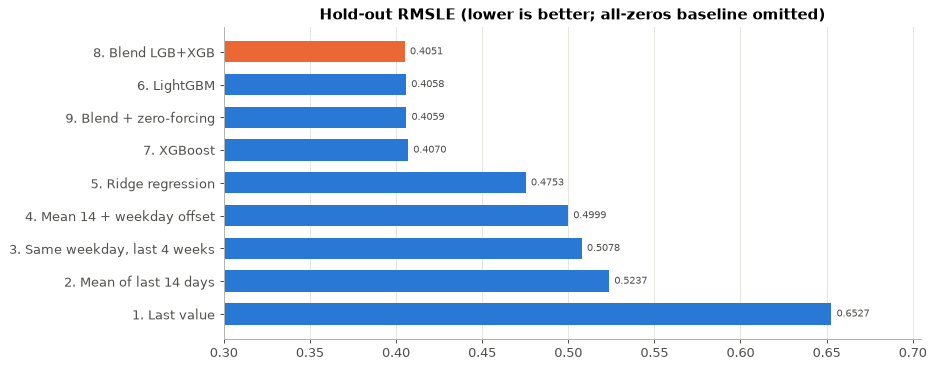

In [23]:
res = pd.DataFrame(results).T
res['RMSLE'] = res.RMSLE.astype(float)
NAIVE = ['1. Last value', '2. Mean of last 14 days', '3. Same weekday, last 4 weeks', '4. Mean 14 + weekday offset']
res['vs. best naive'] = (res.RMSLE / res.loc[NAIVE, 'RMSLE'].min() - 1).map('{:+.1%}'.format)
display(res.sort_values('RMSLE'))

plot = res.drop('0. All zeros').sort_values('RMSLE', ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
best = plot.RMSLE.idxmin()
ax.barh(plot.index, plot.RMSLE, color=[ORANGE if i == best else BLUE for i in plot.index], height=0.65)
for y, v in enumerate(plot.RMSLE):
    ax.text(v + 0.003, y, f'{v:.4f}', va='center', fontsize=8, color='#52514e')
ax.set_xlim(0.3, plot.RMSLE.max() * 1.08); ax.grid(axis='y', visible=False)
ax.set_title('Hold-out RMSLE (lower is better; all-zeros baseline omitted)')
plt.show()

### 3.6 Diagnostics

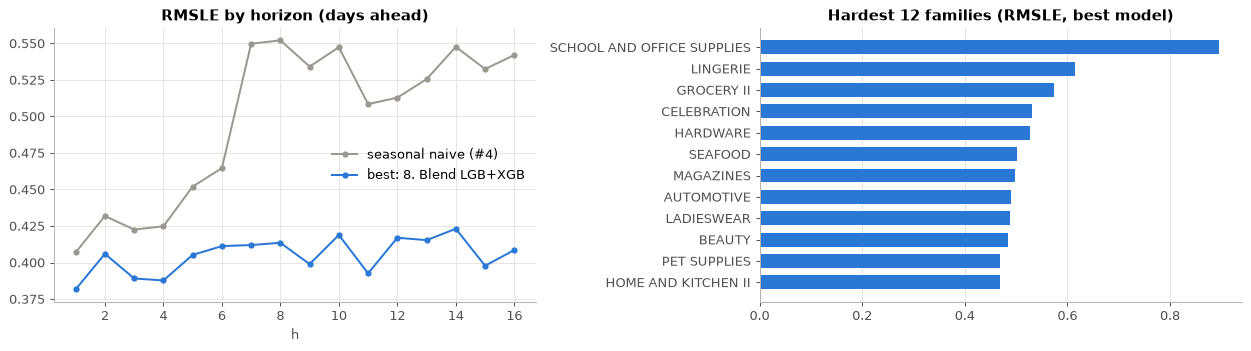

date
2017-07-26    0.382
2017-07-27    0.406
2017-07-28    0.389
2017-07-29    0.388
2017-07-30    0.405
2017-07-31    0.411
2017-08-01    0.412
2017-08-02    0.414
2017-08-03    0.399
2017-08-04    0.419
2017-08-05    0.393
2017-08-06    0.417
2017-08-07    0.415
2017-08-08    0.423
2017-08-09    0.398
2017-08-10    0.409


In [24]:
BEST = '9. Blend + zero-forcing' if USE_ZERO_FORCING else '8. Blend LGB+XGB'
best_pred = val_preds[BEST]
d = va[['h', 'family', 'date']].copy()
d['se'] = (best_pred - y_va) ** 2
d['se_naive'] = (np.clip(va['mean_14'] + va['dow_ratio_8w'], 0, None) - y_va) ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_h = d.groupby('h')[['se', 'se_naive']].mean() ** 0.5
axes[0].plot(by_h.index, by_h.se_naive, color=GREY, marker='o', ms=4, label='seasonal naive (#4)')
axes[0].plot(by_h.index, by_h.se, color=BLUE, marker='o', ms=4, label=f'best: {BEST}')
axes[0].set_title('RMSLE by horizon (days ahead)'); axes[0].set_xlabel('h'); axes[0].legend()
by_f = (d.groupby('family').se.mean() ** 0.5).sort_values().tail(12)
axes[1].barh(by_f.index, by_f.values, color=BLUE, height=0.65); axes[1].grid(axis='y', visible=False)
axes[1].set_title('Hardest 12 families (RMSLE, best model)')
plt.tight_layout(); plt.show()
print(d.groupby('date').se.mean().pow(0.5).round(3).to_string())

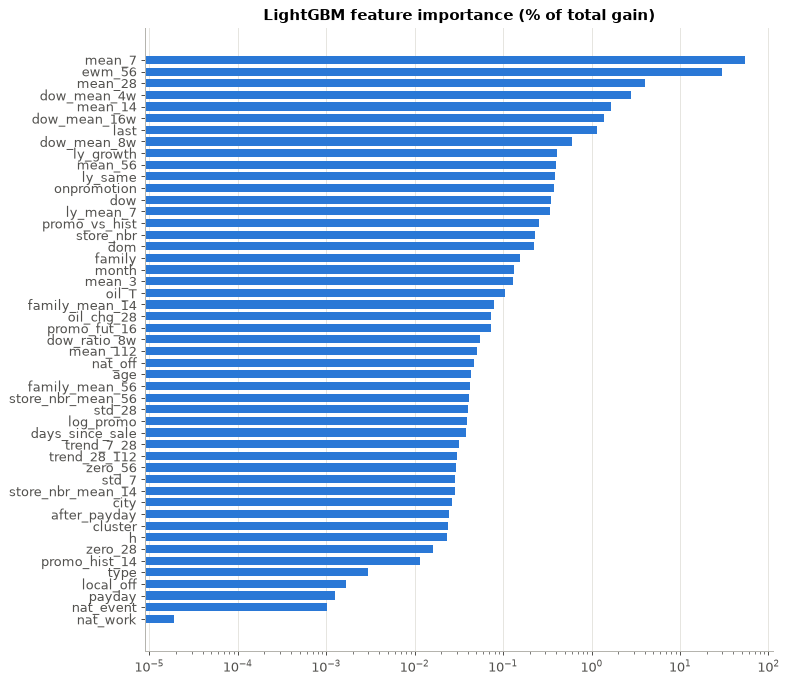

In [25]:
imp = pd.Series(lgb_model.feature_importance('gain'), index=FEATURES).sort_values()
imp = imp / imp.sum() * 100
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(imp.index, imp.values, color=BLUE, height=0.7); ax.grid(axis='y', visible=False)
ax.set_title('LightGBM feature importance (% of total gain)'); ax.set_xscale('log')
plt.show()

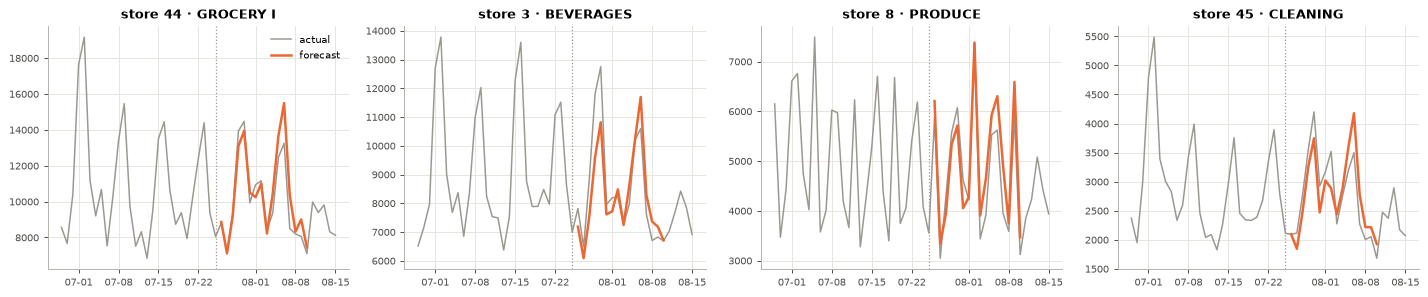

In [26]:
# Visual check: actual vs. predicted for a few big series in the hold-out window
va_plot = va[['store_nbr', 'family', 'date']].assign(actual=np.expm1(y_va), pred=np.expm1(best_pred))
examples = [(44, 'GROCERY I'), (3, 'BEVERAGES'), (8, 'PRODUCE'), (45, 'CLEANING')]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (s, f) in zip(axes, examples):
    hist = train_recent[(train_recent.store_nbr == s) & (train_recent.family == f) & (train_recent.date > VAL_ORIGIN - pd.Timedelta(days=28))]
    cur = va_plot[(va_plot.store_nbr.astype(int) == s) & (va_plot.family.astype(str) == f)].sort_values('date')
    ax.plot(hist.date, hist.sales, color=GREY, lw=1.2, label='actual')
    ax.plot(cur.date, cur.pred, color=ORANGE, lw=2, label='forecast')
    ax.axvline(VAL_ORIGIN, color=GREY, ls=':', lw=1)
    ax.set_title(f'store {s} · {f}', fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d')); ax.tick_params(labelsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Modelling takeaways

| model | hold-out RMSLE |
|---|---|
| last value | 0.653 |
| 14-day mean | 0.524 |
| same weekday, last 4 weeks | 0.508 |
| 14-day mean + weekday offset (best naive) | 0.500 |
| Ridge regression | 0.475 |
| XGBoost | 0.407 |
| LightGBM | 0.406 |
| **Blend 0.6·LGB + 0.4·XGB** | **0.405** |

* **Gradient boosting beats the best seasonal-naive baseline by ~19%**, and linear Ridge regression by ~15%. The gain grows with horizon: naive error jumps after day 6, when the "last 7 days" level becomes stale, while the tree models stay at ~0.39–0.42 throughout.
* **Most important features**: the level features (`ewm_56`, `mean_7`, `mean_14`), then the same-weekday means, then promotion and calendar features. Holiday flags carry little gain overall; they matter on the few days they fire.
* **Blending** LightGBM and XGBoost helps slightly (0.4058 → 0.4051). The two learners make similar errors, so the gain is small.
* **Zero-forcing did not help** (0.4051 → 0.4059). Some series that were silent for 56 days start selling again (e.g. SCHOOL AND OFFICE SUPPLIES before the school year), and the model already predicts ≈0 for truly dead series. It is therefore off in the submission.
* **Last-year features** (value 364 days back, last year's change from origin to target) improved the blend from 0.4066 to 0.4051.
* **Hardest family**: SCHOOL AND OFFICE SUPPLIES (RMSLE ≈ 0.9) because of its back-to-school surge in Aug–Sep. The test window falls in that season, so expect this family to dominate the error there too.

## 4. Final model & submission

Refit LightGBM and XGBoost on **all** origins (now including the hold-out period, i.e. targets up to
2017-08-15) with the number of rounds found by early stopping (+10% for the larger dataset), blend with
the hold-out weight, apply zero-forcing only if it helped on the hold-out, and predict from origin 2017-08-15.

In [27]:
_ = gc.collect()
t0 = time.time()
final_origins = origins_until(TEST_ORIGIN)
print(f'{len(final_origins)} origins: {final_origins[0].date()} … {final_origins[-1].date()}')
extra = [make_rows(T) for T in final_origins if T > train_origins[-1]]   # origins added since validation
full = pd.concat([tr] + extra, ignore_index=True)
del extra, tr; _ = gc.collect()
te = make_rows(TEST_ORIGIN, with_target=False)
assert full.origin.nunique() == len(final_origins)
assert te.date.min() == pd.Timestamp('2017-08-16') and te.date.max() == pd.Timestamp('2017-08-31')
print(f'final train rows {len(full):,} | test rows {len(te):,} | {time.time() - t0:.0f}s')

60 origins: 2016-06-07 … 2017-07-25
final train rows 1,710,720 | test rows 28,512 | 1s


In [28]:
t0 = time.time()
lgb_final = lgb.train(LGB_PARAMS, lgb.Dataset(full[FEATURES], label(full.y), categorical_feature=CAT_COLS),
                      num_boost_round=int(LGB_ROUNDS * 1.1))
xgb_final = xgb.train(XGB_PARAMS, xgb.DMatrix(full[FEATURES], label(full.y), enable_categorical=True),
                      num_boost_round=int(XGB_ROUNDS * 1.1))
p_lgb = lgb_final.predict(te[FEATURES])
p_xgb = xgb_final.predict(xgb.DMatrix(te[FEATURES], enable_categorical=True))
p_log = np.clip(W_LGB * p_lgb + (1 - W_LGB) * p_xgb, 0, None)
if USE_ZERO_FORCING:
    p_log = np.where(te.zero_56.values == 1, 0, p_log)
print(f'trained & predicted in {time.time() - t0:.0f}s; zero-forcing applied: {USE_ZERO_FORCING}')

trained & predicted in 279s; zero-forcing applied: False


In [29]:
pred = te[['date', 'store_nbr', 'family']].copy()
pred['store_nbr'] = pred.store_nbr.astype(int); pred['family'] = pred.family.astype(str)
pred['sales'] = np.expm1(p_log)
sub = test.merge(pred, on=['date', 'store_nbr', 'family'], how='left')[['id', 'sales']]
sample = pd.read_csv(DATA / 'sample_submission.csv')
assert len(sub) == len(sample) == 28512 and sub.sales.notna().all() and (sub.sales >= 0).all()
assert set(sub.id) == set(sample.id)
sub = sub.set_index('id').loc[sample.id].reset_index()
sub.to_csv('submission.csv', index=False)
print('submission.csv written:', sub.shape); display(sub.describe().T)

submission.csv written: (28512, 2)


,count,mean,std,min,25%,50%,75%,max
id,28512.0,3.015144e+06,8230.849774,3000888.0,3.008016e+06,3.015144e+06,3.022271e+06,3.029399e+06
sales,28512.0,4.444067e+02,1195.765452,0.0,3.797213e+00,2.778998e+01,2.551051e+02,1.443231e+04


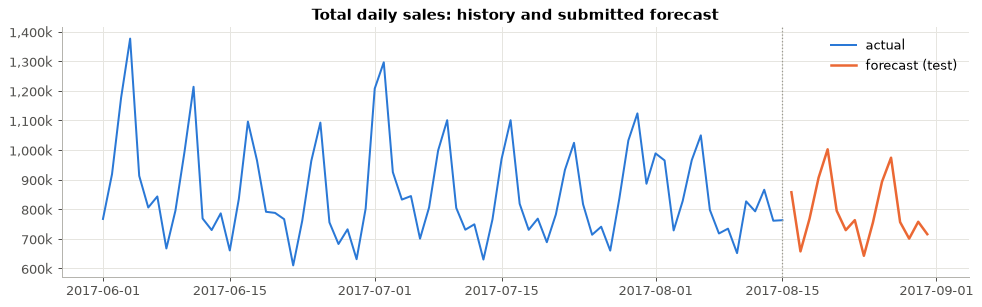

Mean daily total – last 28 days: 837,031 | forecast: 791,933


In [30]:
# Sanity check: forecast total vs. recent history
hist_tot = train_recent.loc[train_recent.date >= '2017-06-01'].groupby('date')['sales'].sum()
fc_tot = pred.groupby('date').sales.sum()
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(hist_tot.index, hist_tot.values, color=BLUE, label='actual')
ax.plot(fc_tot.index, fc_tot.values, color=ORANGE, lw=2, label='forecast (test)')
ax.axvline(TEST_ORIGIN, color=GREY, ls=':', lw=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}k'))
ax.set_title('Total daily sales: history and submitted forecast'); ax.legend(); plt.show()
print(f'Mean daily total – last 28 days: {hist_tot.tail(28).mean():,.0f} | forecast: {fc_tot.mean():,.0f}')

## 5. Conclusions

* **Final model**: a blend (0.6 LightGBM + 0.4 XGBoost) of global gradient-boosted trees. It is trained on 60 weekly forecast origins (Jun 2016 → Jul 2017) × 16 horizons × 1,782 series, with 49 features: level, weekday profile, last-year, promotion, calendar/holiday, oil and store/family attributes. It is refit on all data up to 2017-08-15 for the submission.
* **Expected performance**: the hold-out RMSLE of **0.405** is a single 16-day window, so the leaderboard score will differ somewhat.
* **Sanity check**: the forecast keeps the weekly shape. Its mean daily total (~792k) is slightly below the last 28 days (~837k), consistent with the second half of August being quieter than the start-of-month payday period.

**Ideas to improve further**

1. Model SCHOOL AND OFFICE SUPPLIES separately, or add region-specific school-calendar features (Sierra vs. Costa start dates).
2. Add more validation folds (several origins) to tune hyperparameters and blend weights more robustly.
3. Train per-family or per-horizon models, or add a recursive/NN model (e.g. N-BEATS / TFT) for ensemble diversity.
4. Use a longer history (2015 onward) on a machine with more free RAM; this run was limited to ~2 GB.